# QAOA Max-Cut with Classiq: cloud `minimize` vs CUDA-Q on CPU and GPU

One Classiq model, optimized three ways:

| | Optimization loop runs | ⟨H⟩ is computed by |
|---|---|---|
| **A. Classiq `minimize`** | in the Classiq cloud | Classiq's default simulator, estimated from shots |
| **B. CUDA-Q `qpp-cpu`** | on this machine | CUDA-Q's default CPU simulator: exact `cudaq.observe` |
| **C. CUDA-Q `metal`** (`nvidia` on an NVIDIA GPU) | on this machine | the Apple GPU via [cudaq-metal](https://github.com/vivanwin/cudaq-metal): exact, batched `cudaq.observe` |

B and C run the quantum program Classiq synthesized, exported with `qprog_to_cudaq_kernel`.
All three use the same optimizer (SciPy COBYLA, which is also what `minimize` runs
server-side), the same starting point and the same iteration budget. What differs is
where and how each evaluation of ⟨H⟩ happens.

The problem is **Max-Cut on a random 4-regular graph**, one qubit per node. Random 4-regular
graphs exist for every size from 5 nodes up, so the demo scales from 8 to 30 qubits by changing
`NUM_QUBITS`. Section 7 does exactly that and plots the three approaches side by side.

## 0. Setup

```bash
# Apple Silicon Mac
pip install cudaq==0.16.0 "classiq>=1.35" networkx scipy matplotlib pandas
pip install git+https://github.com/vivanwin/cudaq-metal.git

# Linux with an NVIDIA GPU: no cudaq-metal; this notebook then uses the `nvidia` target
pip install cudaq "classiq>=1.35" networkx scipy matplotlib pandas
```

Classiq 1.35 or newer is needed: it is the first version whose `qprog_to_cudaq_kernel`
converts the high-level model below. Classiq needs a one-time `classiq.authenticate()`
on each machine.

In [1]:
import datetime
import functools
import operator
import os
import platform
import subprocess
import time
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.optimize
from matplotlib.ticker import FixedLocator, NullLocator

try:
    import cudaq_metal  # noqa: F401  Apple Silicon only: adds the "metal" target. Import before cudaq.
except ImportError:
    cudaq_metal = None
warnings.filterwarnings("ignore", message="The CUDA-Q `sample` and `observe`")
import cudaq
import classiq
from classiq import (CArray, CReal, Output, Pauli, Preferences, QArray, QBit, RX, allocate,
                     apply_to_all, get_transpiled_circuit_metrics, hadamard_transform,
                     pauli_operator_to_cudaq_spin_op, phase, qfunc, qprog_to_cudaq_kernel,
                     repeat, synthesize)
from classiq.execution import ExecutionSession

# classiq.authenticate()  # once per machine

assert tuple(int(x) for x in classiq.__version__.split(".")[:2]) >= (1, 35), \
    "this notebook needs classiq >= 1.35"

if cudaq.has_target("metal"):
    GPU_TARGET = "metal"
elif cudaq.num_available_gpus() > 0:
    GPU_TARGET = "nvidia"
else:
    GPU_TARGET = None
print(f"classiq {classiq.__version__} | {cudaq.__version__.split(' (')[0]} | GPU target: {GPU_TARGET}")

classiq 1.35.0 | CUDA-Q Version 0.16.0 | GPU target: metal


In [2]:
NUM_QUBITS = 16      # one qubit per graph node: anything from 8 to 30
NUM_LAYERS = 2       # QAOA depth p
MAX_ITER = 40        # COBYLA iterations: the same budget for every backend
CPU_MAX_QUBITS = 17  # qpp-cpu needs ~3 s per evaluation at 17 qubits, doubling per qubit
GRAPH_SEED = 2026

## 1. The problem: Max-Cut on a random 4-regular graph

Split the nodes into two groups so that as many edges as possible connect the two groups.
Every node has exactly 4 neighbours, so the graph has 2n edges. At these sizes a small
integer program finds the exact maximum cut in well under a second; we use it only to
score the QAOA results.

16 nodes, 32 edges, maximum cut = 28


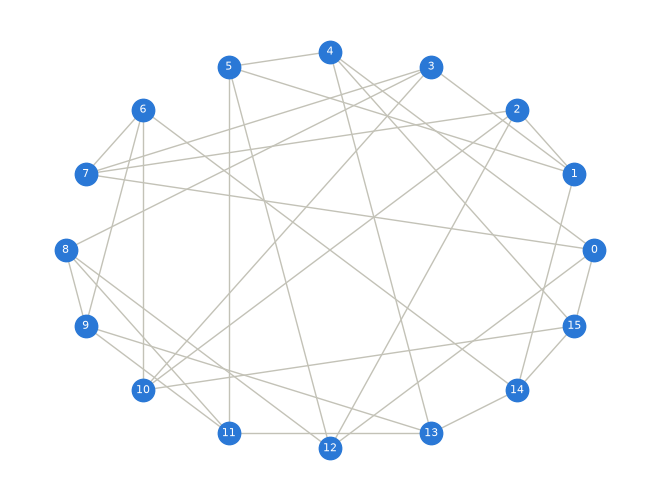

In [3]:
def make_graph(n, seed=GRAPH_SEED):
    """Random 4-regular graph on n nodes (exists for every n >= 5)."""
    return nx.random_regular_graph(4, n, seed=seed)


def max_cut(graph):
    """Exact Max-Cut as an integer program (HiGHS via SciPy)."""
    n, edges = graph.number_of_nodes(), list(graph.edges())
    m = len(edges)
    # Variables: x_i = side of node i, y_e = 1 if edge e is cut. Maximize sum(y).
    A = np.zeros((2 * m, n + m))
    for k, (i, j) in enumerate(edges):
        A[2 * k, [i, j, n + k]] = [-1, -1, 1]     # y_e <= x_i + x_j
        A[2 * k + 1, [i, j, n + k]] = [1, 1, 1]   # y_e <= 2 - x_i - x_j
    upper_bounds = np.r_[0, np.ones(n + m - 1)]  # x_0 = 0: a cut and its mirror image are the same
    res = scipy.optimize.milp(
        np.r_[np.zeros(n), -np.ones(m)],
        constraints=scipy.optimize.LinearConstraint(A, -np.inf, np.tile([0, 2], m)),
        integrality=np.ones(n + m), bounds=scipy.optimize.Bounds(0, upper_bounds))
    return round(-res.fun)


graph = make_graph(NUM_QUBITS)
MAX_CUT = max_cut(graph)
print(f"{NUM_QUBITS} nodes, {graph.number_of_edges()} edges, maximum cut = {MAX_CUT}")
nx.draw_circular(graph, node_size=260, node_color="#2a78d6", edge_color="#c3c2b7",
                 with_labels=True, font_color="white", font_size=8)
plt.show()

## 2. The Classiq model

QAOA prepares $|\gamma,\beta\rangle = \prod_{l=1}^{p} e^{-i\beta_l B}\, e^{-i\gamma_l C}\, |+\rangle^{\otimes n}$,
where $C$ counts the cut edges and $B = \sum_i X_i$. The model says exactly that, starting
from the cost function itself:

- `cut(v)` is the number of cut edges, written as an arithmetic expression of the qubits.
- `phase(-cut(v), γ)` multiplies each basis state $|x\rangle$ by $e^{-i\gamma\,\mathrm{cut}(x)}$,
  which is $e^{-i\gamma C}$.
- `apply_to_all(lambda q: RX(2β, q), v)` is $e^{-i\beta B}$, and `repeat` stacks $p$ layers.

No gates are written by hand: Classiq's synthesis engine turns the expression into a
circuit. `Preferences(standalone=True)` makes the synthesized program self-contained, with
library blocks such as the one `phase` becomes defined inside it. `qprog_to_cudaq_kernel`
needs that to export the program to CUDA-Q.

The optimizer minimizes $\langle H\rangle$ with $H = -C$, which maximizes the expected cut.

In [4]:
def qaoa_model(graph, num_layers):
    n, edges = graph.number_of_nodes(), list(graph.edges())

    def cut(v):
        """Number of cut edges: edge (i, j) is cut when v[i] != v[j]."""
        return sum(v[i] * (1 - v[j]) + v[j] * (1 - v[i]) for i, j in edges)

    @qfunc
    def main(params: CArray[CReal, 2 * num_layers], v: Output[QArray[QBit, n]]):
        allocate(v)
        hadamard_transform(v)
        repeat(num_layers, lambda l: [
            phase(-cut(v), params[l]),                                     # exp(-i gamma_l C)
            apply_to_all(lambda q: RX(2 * params[num_layers + l], q), v),  # exp(-i beta_l B)
        ])

    return main


def cost_hamiltonian(graph):
    """H = sum over edges of (Z_i Z_j - 1)/2 = -(number of cut edges)."""
    terms = [0.5 * Pauli.Z(i) * Pauli.Z(j) for i, j in graph.edges()]
    return functools.reduce(operator.add, terms) - 0.5 * len(terms) * Pauli.I(0)


def initial_params(num_layers, dt=0.75):
    """Linear ramp, a discretized annealing path: gamma grows, beta shrinks."""
    s = (np.arange(num_layers) + 0.5) / num_layers
    return np.r_[dt * s, dt * (1 - s)].tolist()


def synthesize_qaoa(graph, num_layers):
    return synthesize(qaoa_model(graph, num_layers), preferences=Preferences(standalone=True))


t0 = time.perf_counter()
qprog = synthesize_qaoa(graph, NUM_LAYERS)
H = cost_hamiltonian(graph)
X0 = initial_params(NUM_LAYERS)
metrics = get_transpiled_circuit_metrics(qprog)
print(f"synthesized in {time.perf_counter() - t0:.1f} s: width {metrics.width}, depth {metrics.depth}")
print(f"H has {graph.number_of_edges()} ZZ terms; start at gamma, beta = {np.round(X0, 3).tolist()}")

synthesized in 6.6 s: width 16, depth 75
H has 32 ZZ terms; start at gamma, beta = [0.188, 0.562, 0.562, 0.188]


## 3. A: Classiq `minimize` in the cloud

One call: Classiq runs the whole COBYLA loop server-side, estimating ⟨H⟩ from 2,048 shots
per iteration (the default) on its default simulator, and returns the cost and parameters
of every iteration. `variational_minimize` is the current name of `minimize`.

In [5]:
def optimize_classiq(qprog, H, x0, max_iter):
    with ExecutionSession(qprog) as es:
        t0 = time.perf_counter()
        trace = es.variational_minimize(H, {"params": list(x0)}, max_iteration=max_iter)
        seconds = time.perf_counter() - t0
    return dict(seconds=seconds, iterations=len(trace), trace=[cost for cost, _ in trace],
                params=list(trace[-1][1]["params"]))   # last iteration, as Classiq's own QAOA uses


classiq_run = optimize_classiq(qprog, H, X0, MAX_ITER)
print(f"Classiq minimize: {classiq_run['iterations']} iterations in {classiq_run['seconds']:.1f} s")

Classiq minimize: 40 iterations in 9.9 s


## 4. B and C: the same program in CUDA-Q

`qprog_to_cudaq_kernel` turns the synthesized program into a CUDA-Q kernel and
`pauli_operator_to_cudaq_spin_op` turns `H` into a `cudaq.SpinOperator`. Then each COBYLA
step is one `cudaq.observe`: the exact expectation value from the statevector, no shots.
`rhobeg=1.0` is SciPy's default, the same step size Classiq's optimizer starts with.

One practical detail: the converted kernel is a CUDA-Q *builder* kernel, and CUDA-Q 0.16
wraps a builder kernel anew on every `observe` or `sample` call. Each wrap walks the
Python call stack, which costs about 7 ms per call inside Jupyter, more than simulating
20 qubits on the GPU. `wrap_once` builds that wrapper a single time. This speeds up every
CUDA-Q target alike and changes no results.

In [6]:
def wrap_once(kernel):
    """Reuse one CUDA-Q wrapper for a builder kernel (mk_decorator is internal: fall back)."""
    try:
        from cudaq.kernel.kernel_decorator import mk_decorator
        return mk_decorator(kernel)
    except Exception:
        return kernel


class CudaqProgram:
    """A synthesized Classiq program as a CUDA-Q kernel, with H as a CUDA-Q spin operator.

    The kernel takes the CArray[CReal] `params` as one list of floats.
    """

    def __init__(self, qprog, H):
        self.kernel = wrap_once(qprog_to_cudaq_kernel(qprog))
        self.spin_op = pauli_operator_to_cudaq_spin_op(H)

    def energy(self, params):
        """Exact <H> from the statevector, on the current target."""
        return cudaq.observe(self.kernel, self.spin_op, [float(p) for p in params]).expectation()

    def sample(self, params, shots):
        return cudaq.sample(self.kernel, [float(p) for p in params], shots_count=shots)


def optimize_cudaq(target, program, x0, max_iter):
    cudaq.set_target(target)
    trace = []

    def energy(params):
        trace.append(program.energy(params))
        return trace[-1]

    t0 = time.perf_counter()
    res = scipy.optimize.minimize(energy, x0, method="COBYLA",
                                  options={"maxiter": max_iter, "rhobeg": 1.0})
    return dict(seconds=time.perf_counter() - t0, iterations=len(trace), trace=trace,
                params=list(res.x), energy=float(res.fun))


def exact_energy(program, params, n):
    """<H> at these parameters, from the fastest local simulator that can hold n qubits."""
    target = GPU_TARGET or ("qpp-cpu" if n <= CPU_MAX_QUBITS else None)
    if target is None:
        return float("nan")
    cudaq.set_target(target)
    return program.energy(params)


t0 = time.perf_counter()
program = CudaqProgram(qprog, H)
print(f"converted to a CUDA-Q kernel in {time.perf_counter() - t0:.2f} s")

runs = {"Classiq minimize (cloud)": classiq_run}
if NUM_QUBITS <= CPU_MAX_QUBITS:
    runs["CUDA-Q qpp-cpu"] = optimize_cudaq("qpp-cpu", program, X0, MAX_ITER)
if GPU_TARGET:
    runs[f"CUDA-Q {GPU_TARGET}"] = optimize_cudaq(GPU_TARGET, program, X0, MAX_ITER)
for name, run in list(runs.items())[1:]:
    print(f"{name}: {run['iterations']} iterations in {run['seconds']:.2f} s")

converted to a CUDA-Q kernel in 0.06 s


CUDA-Q qpp-cpu: 40 iterations in 47.21 s
CUDA-Q metal: 40 iterations in 0.11 s


## 5. Compare

Wall time is what you wait for, from starting the optimizer to having parameters back.
Classiq's includes the cloud round trips; that is part of what `minimize` costs. To score
all three the same way, the parameters each optimizer returns are evaluated exactly on the
local simulator and turned into an approximation ratio: expected cut ÷ maximum cut.

In [7]:
classiq_run["energy"] = exact_energy(program, classiq_run["params"], NUM_QUBITS)
summary = pd.DataFrame({
    name: {"iterations": run["iterations"],
           "wall time (s)": run["seconds"],
           "per iteration (ms)": 1e3 * run["seconds"] / run["iterations"],
           "expected cut": -run["energy"],
           "approx. ratio": -run["energy"] / MAX_CUT}
    for name, run in runs.items()}).T
display(summary.style.format({"iterations": "{:.0f}", "wall time (s)": "{:.2f}",
                              "per iteration (ms)": "{:,.1f}", "expected cut": "{:.2f}",
                              "approx. ratio": "{:.3f}"}))
fastest = min(runs, key=lambda k: runs[k]["seconds"])
for name, run in runs.items():
    if name != fastest:
        ratio = run["seconds"] / runs[fastest]["seconds"]
        print(f"{fastest} is {ratio:,.0f}x" if ratio >= 10 else f"{fastest} is {ratio:.1f}x",
              f"faster than {name}")

,iterations,wall time (s),per iteration (ms),expected cut,approx. ratio
Classiq minimize (cloud),40,9.86,246.5,22.91,0.818
CUDA-Q qpp-cpu,40,47.21,"1,180.1",22.91,0.818
CUDA-Q metal,40,0.11,2.8,22.91,0.818


CUDA-Q metal is 88x faster than Classiq minimize (cloud)
CUDA-Q metal is 419x faster than CUDA-Q qpp-cpu


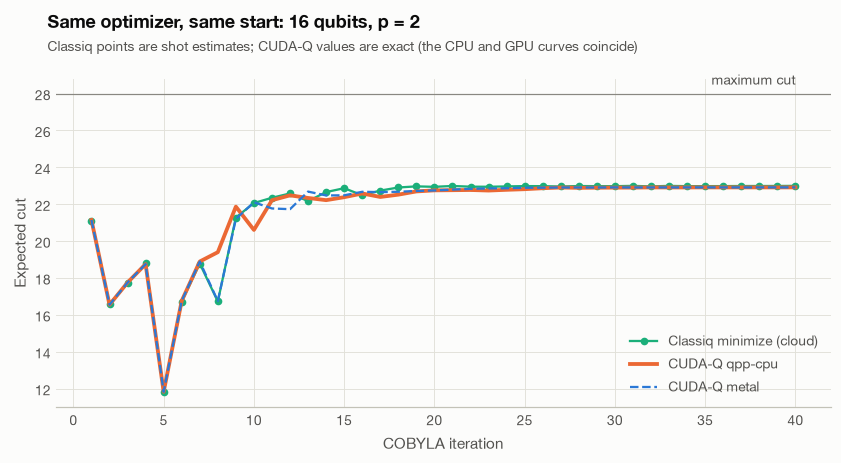

In [8]:
LIGHT = dict(surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#898781",
             grid="#e1e0d9", axis="#c3c2b7",
             series={"metal": "#2a78d6", "qpp-cpu": "#eb6834", "classiq": "#1baf7a", "nvidia": "#eda100"})
DARK = dict(surface="#1a1a19", ink="#f0efec", ink2="#c3c2b7", muted="#898781",
            grid="#2c2c2a", axis="#383835",
            series={"metal": "#3987e5", "qpp-cpu": "#d95926", "classiq": "#199e70", "nvidia": "#c98500"})
plt.rcParams["font.family"] = ["Helvetica Neue", "DejaVu Sans"]


def style_axes(ax, t):
    ax.set_facecolor(t["surface"])
    ax.tick_params(colors=t["muted"], labelcolor=t["ink2"], labelsize=9, length=0)
    ax.grid(True, which="major", color=t["grid"], linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(t["axis"])


def backend_of(name):
    return "classiq" if name.startswith("Classiq") else name.split()[1]


t = LIGHT
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=110)
fig.patch.set_facecolor(t["surface"])
style_axes(ax, t)
for name, run in runs.items():
    b = backend_of(name)
    its = np.arange(1, len(run["trace"]) + 1)
    exact = b != "classiq"
    ax.plot(its, -np.array(run["trace"]), color=t["series"][b], label=name,
            linewidth=2.5 if b == "qpp-cpu" else 1.5, linestyle="--" if b in ("metal", "nvidia") else "-",
            marker=None if exact else "o", markersize=4, zorder=3 if exact else 2)
ax.axhline(MAX_CUT, color=t["muted"], linewidth=0.8)
ax.annotate("maximum cut", (len(classiq_run["trace"]), MAX_CUT), xytext=(0, 4),
            textcoords="offset points", ha="right", va="bottom", fontsize=9, color=t["ink2"])
ax.set_xlabel("COBYLA iteration", color=t["ink2"], fontsize=10)
ax.set_ylabel("Expected cut", color=t["ink2"], fontsize=10)
leg = ax.legend(loc="lower right", frameon=False, fontsize=9)
for txt in leg.get_texts():
    txt.set_color(t["ink2"])
fig.text(0.08, 0.95, f"Same optimizer, same start: {NUM_QUBITS} qubits, p = {NUM_LAYERS}",
         fontsize=12, fontweight="bold", color=t["ink"])
fig.text(0.08, 0.9, "Classiq points are shot estimates; CUDA-Q values are exact "
         "(the CPU and GPU curves coincide)", fontsize=9, color=t["ink2"])
fig.subplots_adjust(left=0.09, right=0.97, top=0.84, bottom=0.13)
plt.show()

### Under the hood: the whole Hamiltonian in one GPU pass

cudaq-metal takes over shot-free `cudaq.observe`: instead of CUDA-Q's default of handling
each Pauli term separately, all ZZ terms are evaluated in one batched pass over the
statevector on the GPU. CUDA-Q's own switch `CUDAQ_OBSERVE_FROM_SAMPLING=1` turns that
off, so the two paths can be timed against each other. For a ZZ-only cost Hamiltonian the
gain is modest. Hamiltonians with X and Y terms gain much more.

In [9]:
def time_observe(program, params, seconds=1.0):
    program.energy(params)   # warm-up
    calls, t0 = 0, time.perf_counter()
    while time.perf_counter() - t0 < seconds:
        program.energy(params)
        calls += 1
    return (time.perf_counter() - t0) / calls


if GPU_TARGET == "metal":
    cudaq.set_target("metal")
    previous = os.environ.pop("CUDAQ_OBSERVE_FROM_SAMPLING", None)   # restored below
    try:
        batched = time_observe(program, X0)
        os.environ["CUDAQ_OBSERVE_FROM_SAMPLING"] = "1"
        per_term = time_observe(program, X0)
    finally:
        if previous is None:
            os.environ.pop("CUDAQ_OBSERVE_FROM_SAMPLING", None)
        else:
            os.environ["CUDAQ_OBSERVE_FROM_SAMPLING"] = previous
    print(f"one observe at {NUM_QUBITS} qubits, {graph.number_of_edges()} terms: batched "
          f"{1e3 * batched:.2f} ms, term by term {1e3 * per_term:.2f} ms ({per_term / batched:.1f}x)")

one observe at 16 qubits, 32 terms: batched 0.97 ms, term by term 2.68 ms (2.7x)


## 6. The answer: sample the optimized circuit

QAOA's output is a distribution over cuts. Sampling the optimized circuit once on the
GPU gives the cuts it proposes. The mean of the sampled cuts should match the exact
expected cut from `observe`.

mean sampled cut 23.00, exact expected cut 22.91
best sampled cut 28 of maximum 28; P(maximum cut) = 5.0%, a random guess: 0.0031%


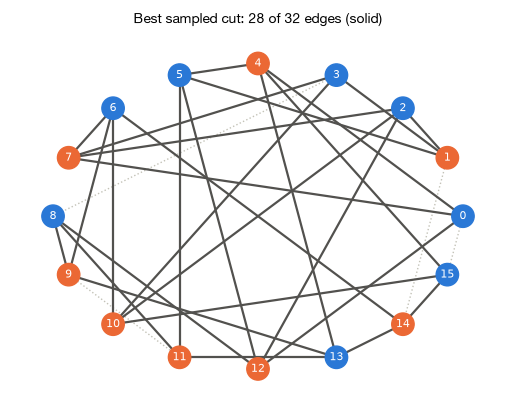

In [10]:
best = runs[fastest]
cudaq.set_target(GPU_TARGET or "qpp-cpu")
counts = program.sample(best["params"], shots=4000)


def cut_size(bits):
    return sum(bits[i] != bits[j] for i, j in graph.edges())


def random_guess_p(graph, best):
    """Chance that a uniformly random split is a maximum cut (enumerates all 2^n splits)."""
    idx = np.arange(2 ** graph.number_of_nodes(), dtype=np.uint32)
    cuts = sum(((idx >> i) ^ (idx >> j)) & 1 for i, j in graph.edges())
    return float(np.mean(cuts == best))


shots = sum(counts.count(b) for b in counts)
mean_cut = sum(cut_size(b) * counts.count(b) for b in counts) / shots
top = max(counts, key=lambda b: (cut_size(b), counts.count(b)))
p_opt = sum(counts.count(b) for b in counts if cut_size(b) == MAX_CUT) / shots
print(f"mean sampled cut {mean_cut:.2f}, exact expected cut {-best['energy']:.2f}")
print(f"best sampled cut {cut_size(top)} of maximum {MAX_CUT}; P(maximum cut) = {p_opt:.1%}"
      + (f", a random guess: {100 * random_guess_p(graph, MAX_CUT):.2g}%" if NUM_QUBITS <= 22 else ""))

colors = [LIGHT["series"]["metal"] if top[i] == "0" else LIGHT["series"]["qpp-cpu"] for i in graph.nodes()]
cut_edges = [(i, j) for i, j in graph.edges() if top[i] != top[j]]
pos = nx.circular_layout(graph)
nx.draw_networkx_edges(graph, pos, edgelist=[e for e in graph.edges() if e not in cut_edges],
                       edge_color="#c3c2b7", style="dotted")
nx.draw_networkx_edges(graph, pos, edgelist=cut_edges, edge_color="#52514e", width=1.6)
nx.draw_networkx_nodes(graph, pos, node_color=colors, node_size=260)
nx.draw_networkx_labels(graph, pos, font_color="white", font_size=8)
plt.title(f"Best sampled cut: {cut_size(top)} of {graph.number_of_edges()} edges (solid)", fontsize=10)
plt.axis("off")
plt.show()

## 7. Scaling from 8 to 30 qubits

The same experiment for every size from 8 qubits up: synthesize, then run each backend
with the same 40-iteration budget. A backend keeps growing until one of its runs takes
longer than `TIME_LIMIT_S` (one minute). That size is still recorded, but no larger size
is launched for that backend. Each backend also has a hard ceiling:

- **Classiq**: the default simulator accepts at most 28 qubits.
- **qpp-cpu**: 17 qubits.
- **metal**: 30 qubits on a 24 GB Mac (an 8 GiB statevector; see the cudaq-metal README).

One row per (backend, device, size) goes to `results/qaoa_scaling.csv` as soon as it is
measured, and rows already in the file are skipped. So with the saved results this cell
measures nothing new; delete the file to measure again.

In [11]:
RUN_SWEEP = True
TIME_LIMIT_S = 60    # a run slower than this is the last size measured for that backend
SWEEP_SIZES = range(8, 31)
SWEEP_BACKENDS = {"classiq": 28, "qpp-cpu": CPU_MAX_QUBITS}   # backend -> largest size to run
if GPU_TARGET:
    SWEEP_BACKENDS[GPU_TARGET] = 30
RESULTS_CSV = os.path.join("results", "qaoa_scaling.csv")


@functools.cache
def device_name(backend):
    if backend == "classiq":
        return "Classiq cloud simulator"
    try:
        if backend == "nvidia":
            out = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
                                 capture_output=True, text=True, check=True).stdout
            return out.splitlines()[0].strip()
        if platform.system() == "Darwin":
            return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                                  capture_output=True, text=True, check=True).stdout.strip()
        with open("/proc/cpuinfo") as f:
            return next(l.split(":", 1)[1].strip() for l in f if l.startswith("model name"))
    except Exception:
        return platform.processor() or platform.machine()


def optimize_classiq_with_retry(qprog, H, x0, max_iter, attempts=3):
    for attempt in range(attempts):
        try:
            return optimize_classiq(qprog, H, x0, max_iter)
        except Exception as e:
            if "too many qubits" in str(e) or attempt == attempts - 1:
                raise
            print(f"    Classiq attempt {attempt + 1} failed ({type(e).__name__}), retrying")
            time.sleep(10)


def run_scaling(backends, sizes, csv_path=RESULTS_CSV, time_limit=TIME_LIMIT_S):
    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    done, last_size = set(), {}   # last_size: backend -> size whose run exceeded time_limit
    if os.path.exists(csv_path):
        old = pd.read_csv(csv_path)
        done = set(zip(old.backend, old.device, old.n))
        for (b, dev), rows in old[old.seconds > time_limit].groupby(["backend", "device"]):
            last_size[b, dev] = rows.n.min()
    measured = 0
    for n in sizes:
        todo = [b for b, n_max in backends.items()
                if n <= min(n_max, last_size.get((b, device_name(b)), n_max))
                and (b, device_name(b), n) not in done]
        if not todo:
            continue
        measured += len(todo)
        g = make_graph(n)
        H_n = cost_hamiltonian(g)
        qprog_n = synthesize_qaoa(g, NUM_LAYERS)
        program_n = CudaqProgram(qprog_n, H_n)
        best_cut = max_cut(g)
        x0 = initial_params(NUM_LAYERS)
        for b in todo:
            try:
                if b == "classiq":
                    run = optimize_classiq_with_retry(qprog_n, H_n, x0, MAX_ITER)
                    run["energy"] = exact_energy(program_n, run["params"], n)
                else:
                    run = optimize_cudaq(b, program_n, x0, MAX_ITER)
            except Exception as e:
                print(f"n={n:2d} {b:8s} FAILED: {type(e).__name__}: {str(e)[:200]}", flush=True)
                continue
            row = dict(backend=b, device=device_name(b), n=n, edges=g.number_of_edges(),
                       layers=NUM_LAYERS, iterations=run["iterations"], seconds=round(run["seconds"], 4),
                       expected_cut=round(-run["energy"], 4), max_cut=best_cut,
                       approx_ratio=round(-run["energy"] / best_cut, 4),
                       classiq=classiq.__version__, cudaq=cudaq.__version__.split(" (")[0].split()[-1],
                       date=datetime.date.today().isoformat())
            pd.DataFrame([row]).to_csv(csv_path, mode="a", header=not os.path.exists(csv_path),
                                       index=False)
            print(f"n={n:2d} {b:8s} {run['iterations']:3d} iterations {run['seconds']:9.2f} s  "
                  f"ratio {row['approx_ratio']:.3f}", flush=True)
            if run["seconds"] > time_limit:
                last_size[b, device_name(b)] = n
                print(f"      {b} took more than {time_limit} s: no larger sizes", flush=True)
    if not measured:
        print(f"nothing new to measure: {csv_path} already has every run for "
              f"{', '.join(backends)} (delete it to measure again)")


if RUN_SWEEP:
    run_scaling(SWEEP_BACKENDS, SWEEP_SIZES)

nothing new to measure: results/qaoa_scaling.csv already has every run for classiq, qpp-cpu, metal (delete it to measure again)


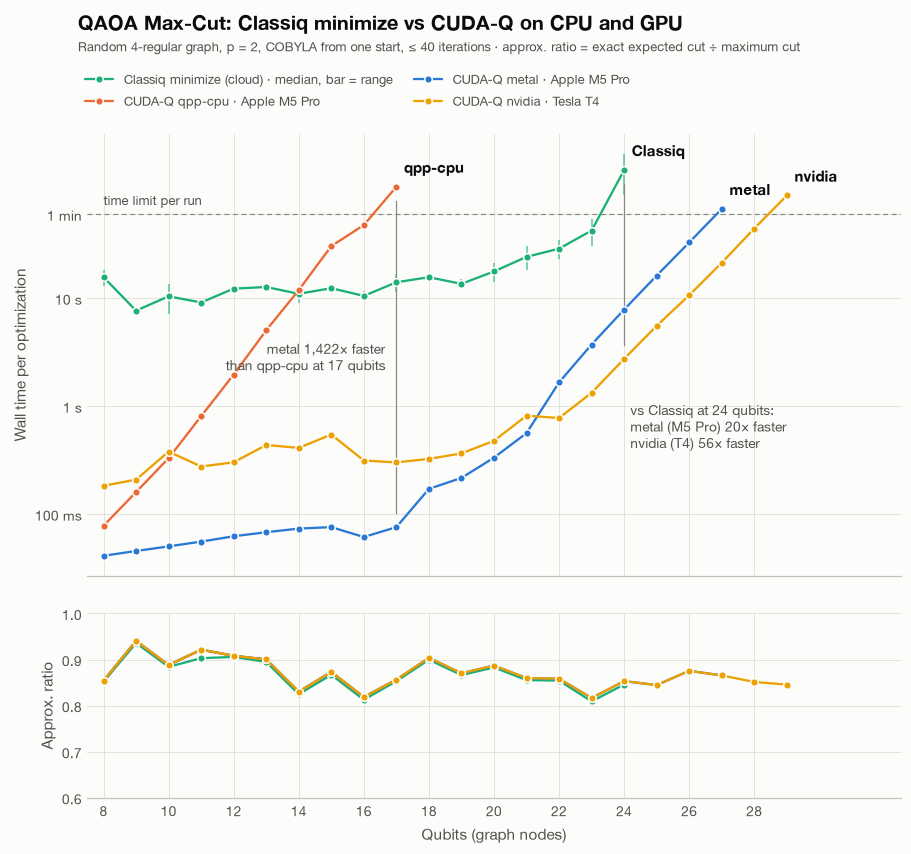

In [12]:
SERIES_ORDER = ["classiq", "qpp-cpu", "metal", "nvidia"]
TIME_TICKS = [0.01, 0.1, 1, 10, 60, 600, 3600]
TIME_LABELS = ["10 ms", "100 ms", "1 s", "10 s", "1 min", "10 min", "1 h"]


def clean_device(device):
    """'Intel(R) Xeon(R) CPU @ 2.00GHz' -> 'Intel Xeon CPU @ 2.00GHz'."""
    return " ".join(device.replace("(R)", "").replace("(TM)", "").split())


def device_tag(device):
    """Short name for chart labels: 'Apple M5 Pro' -> 'M5 Pro', 'Tesla T4' -> 'T4'."""
    words = clean_device(device).split("@")[0].split()
    return " ".join(w for w in words if w not in {"Apple", "Intel", "AMD", "NVIDIA", "Tesla", "CPU"}) or device


def series_label(backend, device):
    if backend == "classiq":
        return "Classiq minimize (cloud)"
    return f"CUDA-Q {backend} · {clean_device(device)}"


def summarize(df):
    """One row per (backend, device, size): the median over repeated runs, and their range."""
    return (df.groupby(["backend", "device", "n"])
              .agg(seconds=("seconds", "median"), lo=("seconds", "min"), hi=("seconds", "max"),
                   runs=("seconds", "size"), approx_ratio=("approx_ratio", "median"),
                   layers=("layers", "max"), iterations=("iterations", "max"))
              .reset_index())


def plot_scaling(df, t=LIGHT, dpi=110):
    s = summarize(df)
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(8.5, 7.8), dpi=dpi, sharex=True,
                                  gridspec_kw=dict(height_ratios=[3, 1.25], hspace=0.12))
    fig.patch.set_facecolor(t["surface"])
    for a in (ax, ax2):
        style_axes(a, t)
    groups = sorted(s.groupby(["backend", "device"]),
                    key=lambda g: (SERIES_ORDER.index(g[0][0]) if g[0][0] in SERIES_ORDER else 99, g[0][1]))
    direct_labels = len(groups) <= 4          # more lines than that: the legend alone names them
    devices_per_backend = s.groupby("backend").device.nunique()
    seen = {}
    for (b, dev), g in groups:
        g = g.sort_values("n")
        style = dict(color=t["series"].get(b, t["muted"]), linewidth=1.5, solid_capstyle="round",
                     linestyle="-" if b not in seen else "--", marker="o", markersize=5,
                     markeredgewidth=1, markeredgecolor=t["surface"], zorder=3)
        seen[b] = seen.get(b, 0) + 1
        repeated = g[g.runs > 1]
        label = series_label(b, dev) + (" · median, bar = range" if len(repeated) else "")
        ax.plot(g.n, g.seconds, label=label, **style)
        ax.vlines(repeated.n, repeated.lo, repeated.hi, color=style["color"], linewidth=1.3,
                  alpha=0.55, zorder=2)
        ax2.plot(g.n, g.approx_ratio, **style)
        if direct_labels:   # just above the last point, clear of a line still rising past it
            name = "Classiq" if b == "classiq" else b
            if devices_per_backend[b] > 1:
                name += f" ({device_tag(dev)})"
            ax.annotate(name, (g.n.iloc[-1], g.seconds.iloc[-1]), xytext=(5, 7),
                        textcoords="offset points", ha="left", va="bottom", fontsize=9.5,
                        color=t["ink"], fontweight="bold")

    # Headlines. CPU: the first GPU against qpp-cpu on the same machine where there is one.
    # Classiq: every GPU against Classiq's median at the largest size Classiq ran.
    def times(b, dev=None):
        rows = s[(s.backend == b) & ((s.device == dev) if dev else True)]
        return rows.groupby("n").seconds.min()
    gpus = [(b, dev) for (b, dev), _ in groups if b in ("metal", "nvidia")]
    if gpus:
        gpu, gpu_dev = gpus[0]
        cpu = times("qpp-cpu", gpu_dev) if gpu_dev in set(s[s.backend == "qpp-cpu"].device) else times("qpp-cpu")
        common = sorted(set(cpu.index) & set(times(gpu, gpu_dev).index))
        if common:
            n = common[-1]
            slow, fast = cpu[n], times(gpu, gpu_dev)[n]
            ax.plot([n, n], [fast * 1.35, slow / 1.35], color=t["muted"], linewidth=0.8, zorder=2)
            ax.annotate(f"{gpu} {slow / fast:,.0f}× faster\nthan qpp-cpu at {n} qubits",
                        (n, (slow * fast) ** 0.5), xytext=(-7, 0), textcoords="offset points",
                        ha="right", va="center", fontsize=9, color=t["ink2"])
        cl = times("classiq")
        at = [n for n in cl.index if any(n in times(b, d).index for b, d in gpus)]
        if at:
            n = max(at)
            slow = cl[n]
            fast = {f"{b} ({device_tag(d)})": times(b, d)[n] for b, d in gpus if n in times(b, d).index}
            ax.plot([n, n], [min(fast.values()) * 1.35, slow / 1.35], color=t["muted"],
                    linewidth=0.8, zorder=2)
            # Text under the bracket's foot: the GPU lines rise to the right, so the space below
            # and right of their points at this size is empty.
            ax.annotate(f"vs Classiq at {n} qubits:\n"
                        + "\n".join(f"{name} {slow / sec:,.0f}× faster" for name, sec in fast.items()),
                        (n, min(fast.values()) / 2.5), xytext=(4, 0), textcoords="offset points",
                        ha="left", va="top", fontsize=9, color=t["ink2"])

    ax.axhline(TIME_LIMIT_S, color=t["muted"], linewidth=0.8, linestyle=(0, (4, 3)), zorder=1)
    ax.annotate("time limit per run", (df.n.min(), TIME_LIMIT_S), xytext=(0, 4),
                textcoords="offset points", ha="left", va="bottom", fontsize=8.5, color=t["ink2"])
    ax.set_yscale("log")
    lo, hi = s.lo.min(), s.hi.max()
    ticks = [(v, lab) for v, lab in zip(TIME_TICKS, TIME_LABELS) if lo / 3 <= v <= hi * 3]
    ax.yaxis.set_major_locator(FixedLocator([v for v, _ in ticks]))
    ax.yaxis.set_ticklabels([lab for _, lab in ticks])
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_ylabel("Wall time per optimization", color=t["ink2"], fontsize=10)
    ax2.set_ylabel("Approx. ratio", color=t["ink2"], fontsize=10)
    ax2.set_ylim(min(0.6, s.approx_ratio.min() - 0.02), 1.0)
    ax2.set_xlabel("Qubits (graph nodes)", color=t["ink2"], fontsize=10)
    ns = sorted(s.n.unique())
    ax2.set_xticks(range(min(ns), max(ns) + 1, 2))
    ax2.set_xlim(min(ns) - 0.5, max(ns) + (3.5 if direct_labels else 0.8))
    fig.text(0.09, 0.965, "QAOA Max-Cut: Classiq minimize vs CUDA-Q on CPU and GPU",
             fontsize=13, fontweight="bold", color=t["ink"])
    fig.text(0.09, 0.94, f"Random 4-regular graph, p = {int(s.layers.max())}, COBYLA from one start, "
             f"≤ {int(s.iterations.max())} iterations · approx. ratio = exact expected cut ÷ maximum cut",
             fontsize=8.5, color=t["ink2"])
    handles, labels = ax.get_legend_handles_labels()
    leg = fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.085, 0.93), ncol=2,
                     frameon=False, fontsize=8.5, handlelength=2.2, columnspacing=1.6)
    for txt in leg.get_texts():
        txt.set_color(t["ink2"])
    rows = (len(labels) + 1) // 2
    fig.subplots_adjust(left=0.1, right=0.97, top=0.9 - 0.028 * rows, bottom=0.07)
    return fig


if os.path.exists(RESULTS_CSV):
    scaling = pd.read_csv(RESULTS_CSV)
    fig = plot_scaling(scaling)
    plt.show()
    for name, theme in (("qaoa_scaling.png", LIGHT), ("qaoa_scaling-dark.png", DARK)):
        plot_scaling(scaling, theme, dpi=200).savefig(os.path.join("results", name),
                                                      facecolor=theme["surface"])
        plt.close()
else:
    print(f"no {RESULTS_CSV} yet: set RUN_SWEEP = True above")

The saved results come from two machines (November 2026): an Apple M5 Pro running this
notebook locally, and Google Colab with an NVIDIA T4 GPU (`nvidia`). Both ran the Classiq
sweep too. `qpp-cpu` is shown for the M5 Pro only.

- **Classiq** times come from a shared cloud service and vary from run to run, so its line
  is the median of the two sweeps and the bars show their range. At 24 qubits the two runs
  took 218 s and 90 s; two extra runs from the Mac took 66 s and 96 s. The local simulators
  repeat to within a few percent, so their points are single runs.
- **metal vs. T4**: the M5 Pro's GPU is faster up to 21 qubits, 4–7× below 18 qubits where
  fixed per-iteration costs dominate. From 22 qubits the T4 is faster: 2.1× at 22 and about
  3× from 23 to 27 qubits, and it stays under the minute up to 29 qubits (metal: 27).

In [13]:
if os.path.exists(RESULTS_CSV):
    table = scaling.assign(series=[series_label(b, d) for b, d in zip(scaling.backend, scaling.device)])
    display(table.pivot_table(index="n", columns="series", values="seconds", aggfunc="median")
                 .style.format("{:,.2f}", na_rep="–")
                 .set_caption("Wall time per optimization (s), median where a size was run more than once"))

series,CUDA-Q metal · Apple M5 Pro,CUDA-Q nvidia · Tesla T4,CUDA-Q qpp-cpu · Apple M5 Pro,Classiq minimize (cloud)
n,,,,
8,0.04,0.18,0.08,15.65
9,0.05,0.21,0.16,7.66
10,0.05,0.38,0.33,10.40
11,0.06,0.28,0.81,9.11
12,0.06,0.30,1.96,12.26
13,0.07,0.44,5.04,12.68
14,0.07,0.41,11.88,10.97
15,0.08,0.55,30.34,12.37
16,0.06,0.31,47.52,10.49


## 8. Running it on an NVIDIA GPU

On Linux with an NVIDIA GPU (and no cudaq-metal) the setup cell selects CUDA-Q's `nvidia`
target. Like `metal` it simulates in single precision, so the two compare directly. The
saved results include one such run, on Google Colab with a T4. To add another GPU:

1. Put `results/qaoa_scaling.csv` from this repository next to the notebook, so the
   Classiq and existing GPU rows are already there. (Or sweep from an empty file and
   concatenate the two CSVs afterwards: every row names its device, and repeated Classiq
   runs are plotted as a median.)
2. In section 7, set `SWEEP_BACKENDS = {"nvidia": 30}`. Add `"qpp-cpu": 17` to measure
   that machine's CPU too; the Classiq rows don't need repeating. The one-minute
   `TIME_LIMIT_S` applies here as well. To go further, raise it together with the cap and
   `SWEEP_SIZES`: a single-precision statevector takes 8 GiB at 30 qubits and doubles per
   qubit.
3. Run all cells. New rows are tagged with the GPU's name, and the plot draws them as
   their own line.

For a double-precision run use `cudaq.set_target("nvidia", option="fp64")` in `optimize_cudaq`.